# Лабораторная работа 9

Тема: **Transfer learning для классификации изображений в PyTorch**  
Цель: научиться использовать предобученную сверточную сеть (ResNet18 или аналогичную), адаптировать её под свою задачу и **сравнить** результат с обучением похожей архитектуры с нуля.

> Важно: этот ноутбук сделан как задание, а не как готовый отчёт.  
> Код даёт стартовую точку, но основная часть баллов — за ваши эксперименты и ваши живые комментарии.  
> Текстовые ответы должны соответствовать вашим графикам и числам, а не быть универсальными фразами из интернета.


## 1. Ваше предварительное понимание transfer learning

Перед кодом сформулируйте своими словами:
1. Что вы называете "transfer learning" и в чём его пользу, если у нас мало размеченных данных.  
2. Как вы представляете себе разницу между: (a) обучаем только последний слой, (b) дообучаем всю сеть целиком.  
3. Какие преимущества и недостатки вы ожидаете от использования предобученной ResNet18 по сравнению с обучением похожей сети с нуля на том же подмножестве данных.

Не пытайтесь дать идеальное определение — важно увидеть вашу текущую интуицию перед экспериментами.


In [22]:
intro_text = """
1. Transfer Learning - это метод, при котором модель, обученная на одной задаче, используется в качестве начальной точки для обучения на другой, схожей задаче
Польза в том, что если размеченных данных для новой задачи мало, то можно использовать уже обученную на большой базе данных модель и дообучить модель под условия нашей задачи.
2. Когда мы обучаем только последний слой, мы сохраняем "знание" модели о том как получать признаки
Адаптируем только классификатор(разделять признаки не на 10 классов, например, а на 5)
Когда мы обучаем всю модель, то мы позволяем модели находить признаки и зависимости в новых данных, что может привести к лучшей производительности, 
но требует больше данных и времени на обучение, что невилирует преимущество transfer learning
3. Использование предобученной модели сократит время на обучение, но, как я ожидаю, покажет плохую точность, так как данные, на которых училась модель (224х224 каритинки) 
сильно отличаются от  CIFAR-10 (32х32)
Обучение всей модели с нуля должно показать лучшую точность, так как модель сможет адаптироваться к особенностям данных CIFAR-10, но займет больше времени на обучение
"""
print(intro_text)


1. Transfer Learning - это метод, при котором модель, обученная на одной задаче, используется в качестве начальной точки для обучения на другой, схожей задаче
Польза в том, что если размеченных данных для новой задачи мало, то можно использовать уже обученную на большой базе данных модель и дообучить модель под условия нашей задачи.
2. Когда мы обучаем только последний слой, мы сохраняем "знание" модели о том как получать признаки
Адаптируем только классификатор(разделять признаки не на 10 классов, например, а на 5)
Когда мы обучаем всю модель, то мы позволяем модели находить признаки и зависимости в новых данных, что может привести к лучшей производительности, 
но требует больше данных и времени на обучение, что невилирует преимущество transfer learning
3. Использование предобученной модели сократит время на обучение, но, как я ожидаю, покажет плохую точность, так как данные, на которых училась модель (224х224 каритинки) 
сильно отличаются от  CIFAR-10 (32х32)
Обучение всей модели с 

## 2. Импорт библиотек и настройка среды

Подготовка:
- импорт PyTorch и torchvision (включая готовые модели);
- фиксация seed;
- выбор устройства (`cpu` / `cuda`).


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import numpy as np
import random
import matplotlib.pyplot as plt

MY_SEED = 1
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)
random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
print("MY_SEED =", MY_SEED)

Устройство: cpu
MY_SEED = 1


## 3. Данные: подмножество CIFAR‑10 и аугментации

Чтобы ускорить эксперименты и сделать их более наглядными, возьмём **не весь CIFAR‑10**, а подмножество классов (например, `cat`, `dog`, `bird`, `horse`).

Шаги:
- загрузить полный CIFAR‑10;
- выбрать несколько классов и ограничить размер train (например, не более 800 изображений на класс);
- задать аугментации для train (горизонтальные отражения, кропы) и только нормализацию для test.


In [36]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
full_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

all_classes = full_train.classes
print("Все классы CIFAR‑10:", all_classes)

Все классы CIFAR‑10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Выберем несколько классов (в примере — четыре).  
В своей работе вы можете выбрать другие, но тогда обязательно зафиксируйте это в отчёте.


In [37]:
selected_class_names = ["cat", "dog", "bird", "horse"]
class_to_idx_full = {name: i for i, name in enumerate(all_classes)}
selected_class_indices = {class_to_idx_full[name] for name in selected_class_names}

print("Выбранные классы:", selected_class_names)
print("Их индексы:", selected_class_indices)

Выбранные классы: ['cat', 'dog', 'bird', 'horse']
Их индексы: {2, 3, 5, 7}


In [38]:
def subset_by_classes(dataset, selected_idx_set, max_per_class=None):
    indices = []
    counts = {c: 0 for c in selected_idx_set}
    for i, (_, label) in enumerate(dataset):
        if label in selected_idx_set:
            if max_per_class is None or counts[label] < max_per_class:
                indices.append(i)
                counts[label] += 1
    return Subset(dataset, indices)

train_subset = subset_by_classes(full_train, selected_class_indices, max_per_class=800)
test_subset = subset_by_classes(full_test, selected_class_indices, max_per_class=None)

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=False)

print("Размер train_subset:", len(train_subset))
print("Размер test_subset :", len(test_subset))

Размер train_subset: 3200
Размер test_subset : 4000


Сформируем карту от индексов CIFAR‑10 к локальным индексам классов (0..K−1), чтобы правильно использовать `CrossEntropyLoss`.


In [30]:
selected_idx_sorted = sorted(list(selected_class_indices))
cifar_idx_to_local = {cifar_idx: i for i, cifar_idx in enumerate(selected_idx_sorted)}
local_to_name = {i: all_classes[cifar_idx] for i, cifar_idx in enumerate(selected_idx_sorted)}

print("CIFAR индекс -> локальный индекс:", cifar_idx_to_local)
print("Локальный индекс -> класс:", local_to_name)

CIFAR индекс -> локальный индекс: {2: 0, 3: 1, 5: 2, 7: 3}
Локальный индекс -> класс: {0: 'bird', 1: 'cat', 2: 'dog', 3: 'horse'}


## 4. Предобученная модель: ResNet18 и заморозка слоёв

Используем `torchvision.models.resnet18` с предобученными весами (`ImageNet`).  
Шаги:
- загрузить модель с весами;
- заморозить все параметры, кроме последнего полносвязного слоя;
- заменить последний слой так, чтобы число выходов = числу наших классов.


In [31]:
base_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# "Замораживаем" все параметры
for param in base_model.parameters():
    param.requires_grad = False

num_ftrs = base_model.fc.in_features
num_target_classes = len(selected_class_indices)

base_model.fc = nn.Linear(num_ftrs, num_target_classes)
model_tl = base_model.to(device)
print(model_tl.fc)

Linear(in_features=512, out_features=4, bias=True)


### Комментарий: почему мы замораживаем слои?

Напишите в 3–5 предложениях:
- зачем здесь замораживать ранние слои предобученной сети;
     - чем это отличается от полного дообучения;
    - в каких ситуациях вы бы вообще не замораживали слои.


In [23]:
freeze_comment = """
Мы заморозили все слои, кроме последнего, чтобы сохранить извлеченные из огромного объема данных признаки, на которых обучалась модель.
Обучая только последний слой, мы адаптируем модель к нашей конкретной задаче(классификация на 4 класса)
Есть очевидный минус этого подхода: данные, на которых обучалась модель(224х224), сильно отличаются от наших данных(32х32)
Ожидаю, что точность будет низкой

Если не замораживать слои, то модель сможет адаптироваться к особенностям данных CIFAR-10, что может привести к лучшей производительности, 
но требует больше данных и времени на обучение
В этом случае мы теряем приемущества transfer learning, и, фактически, просто работаем с архитектурой ResNet18, которая не подходит под наши данные
"""
print(freeze_comment)


Мы заморозили все слои, кроме последнего, чтобы сохранить извлеченные из огромного объема данных признаки, на которых обучалась модель.
Обучая только последний слой, мы адаптируем модель к нашей конкретной задаче(классификация на 4 класса)
Есть очевидный минус этого подхода: данные, на которых обучалась модель(224х224), сильно отличаются от наших данных(32х32)
Ожидаю, что точность будет низкой

Если не замораживать слои, то модель сможет адаптироваться к особенностям данных CIFAR-10, что может привести к лучшей производительности, 
но требует больше данных и времени на обучение
В этом случае мы теряем приемущества transfer learning, и, фактически, просто работаем с архитектурой ResNet18, которая не подходит под наши данные



## 5. Функции обучения/оценки для transfer learning

Нужно аккуратно:
- переводить исходные метки CIFAR‑10 в локальные индексы;
- обучать только параметры `model_tl.fc`.


In [17]:
criterion = nn.CrossEntropyLoss()
optimizer_tl = torch.optim.Adam(model_tl.fc.parameters(), lr=1e-3)

def map_labels_to_local(labels_tensor):
    mapped = [cifar_idx_to_local[int(l)] for l in labels_tensor]
    return torch.tensor(mapped, dtype=torch.long)

def train_one_epoch_tl(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels_local = map_labels_to_local(labels).to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels_local)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels_local).sum().item()
        total += images.size(0)

    return total_loss / total, total_correct / total

def evaluate_tl(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels_local = map_labels_to_local(labels).to(device)
            outputs = model(images)
            loss = criterion(outputs, labels_local)

            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            total_correct += (preds == labels_local).sum().item()
            total += images.size(0)

    return total_loss / total, total_correct / total

print("Функции train_one_epoch_tl и evaluate_tl определены.")

Функции train_one_epoch_tl и evaluate_tl определены.


## 6. Обучение: transfer learning (только последний слой)

Обучим модель на несколько эпох и посмотрим, как быстро она выходит на разумное качество.


In [35]:
num_epochs_tl = 30
history_tl = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs_tl + 1):
    train_loss, train_acc = train_one_epoch_tl(model_tl, train_loader, optimizer_tl, criterion, device)
    test_loss, test_acc = evaluate_tl(model_tl, test_loader, criterion, device)

    history_tl["train_loss"].append(train_loss)
    history_tl["train_acc"].append(train_acc)
    history_tl["test_loss"].append(test_loss)
    history_tl["test_acc"].append(test_acc)

    print(f"[TL] Эпоха {epoch}/{num_epochs_tl}: "
          f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
          f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

[TL] Эпоха 1/30: train_loss=1.4988, train_acc=0.2306, test_loss=1.4824, test_acc=0.2590


KeyboardInterrupt: 

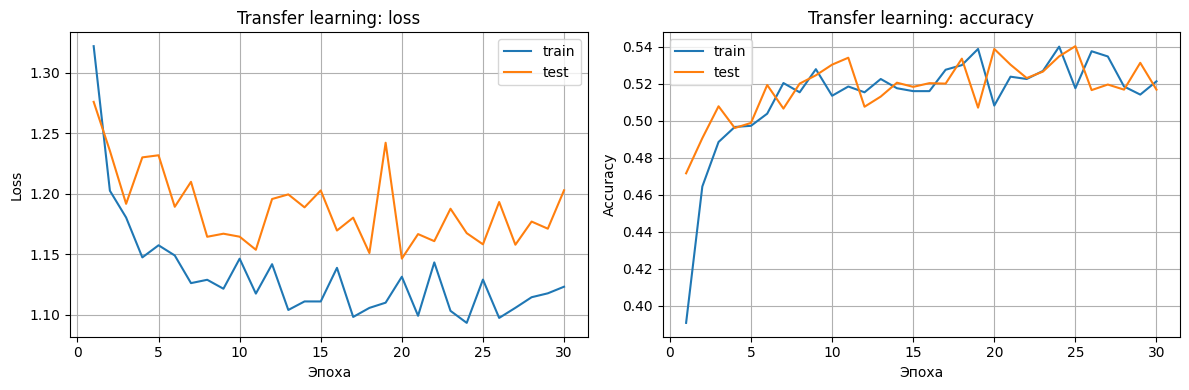

Итоговая точность TL: train=0.5212, test=0.5168


In [19]:
epochs_tl = np.arange(1, num_epochs_tl + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_tl, history_tl["train_loss"], label="train")
plt.plot(epochs_tl, history_tl["test_loss"], label="test")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Transfer learning: loss")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_tl, history_tl["train_acc"], label="train")
plt.plot(epochs_tl, history_tl["test_acc"], label="test")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Transfer learning: accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

print(f"Итоговая точность TL: train={history_tl['train_acc'][-1]:.4f}, test={history_tl['test_acc'][-1]:.4f}")

### Краткий анализ TL‑кривых

Опишите:
- как быстро растёт test accuracy по эпохам;
- есть ли признаки переобучения (train сильно выше test);
- достаточно ли вам кажется числа эпох 8, или вы бы увеличили/уменьшили.


In [25]:
tl_comment = """
1. Начиная ~с 7 эпохи, модель начинает стагнировать, оставаясь около значенияи 0.5 accuracy и 1.2 loss
2. Признаков переобучения нет, но нет и признаков обучения. Модель не может работать с таким маленькими каринками(обучалась она на больших) и упирается в потолок своих возможностей
3. Не думаю, что стоит увеличивать количество эпох, так как модель уже достигла своего потолка. Дальнейшее обучение, в лучшем случае, просто не приведет к улучшению, 
В худшем случае добавление эпох может вызвать переобучение
"""
print(tl_comment)


1. Начиная ~с 7 эпохи, модель начинает стагнировать, оставаясь около значенияи 0.5 accuracy и 1.2 loss
2. Признаков переобучения нет, но нет и признаков обучения. Модель не может работать с таким маленькими каринками(обучалась она на больших) и упирается в потолок своих возможностей
3. Не думаю, что стоит увеличивать количество эпох, так как модель уже достигла своего потолка. Дальнейшее обучение, в лучшем случае, просто не приведет к улучшению, 
В худшем случае добавление эпох может вызвать переобучение



## 7. Обучение похожей модели "с нуля" (без предобученных весов)

Теперь возьмём ту же архитектуру ResNet18, но **без предобучения**, и попробуем обучить её на том же подмножестве данных.

Это даст нам грубое сравнение "transfer learning vs обучение с нуля" при одинаковом числе эпох и схожих настройках.


In [32]:
scratch_model = models.resnet18(weights=None)
scratch_model.fc = nn.Linear(scratch_model.fc.in_features, num_target_classes)
scratch_model = scratch_model.to(device)

optimizer_scratch = torch.optim.Adam(scratch_model.parameters(), lr=1e-3)

def train_one_epoch_scratch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels_local = map_labels_to_local(labels).to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels_local)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels_local).sum().item()
        total += images.size(0)

    return total_loss / total, total_correct / total

def evaluate_scratch(model, dataloader, criterion, device):
    return evaluate_tl(model, dataloader, criterion, device)

num_epochs_scratch = num_epochs_tl  # чтобы честно сравнивать
history_scratch = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs_scratch + 1):
    train_loss, train_acc = train_one_epoch_scratch(scratch_model, train_loader, optimizer_scratch, criterion, device)
    test_loss, test_acc = evaluate_scratch(scratch_model, test_loader, criterion, device)

    history_scratch["train_loss"].append(train_loss)
    history_scratch["train_acc"].append(train_acc)
    history_scratch["test_loss"].append(test_loss)
    history_scratch["test_acc"].append(test_acc)

    print(f"[Scratch] Эпоха {epoch}/{num_epochs_scratch}: "
          f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
          f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

[Scratch] Эпоха 1/30: train_loss=1.3325, train_acc=0.3819, test_loss=1.3001, test_acc=0.4283


KeyboardInterrupt: 

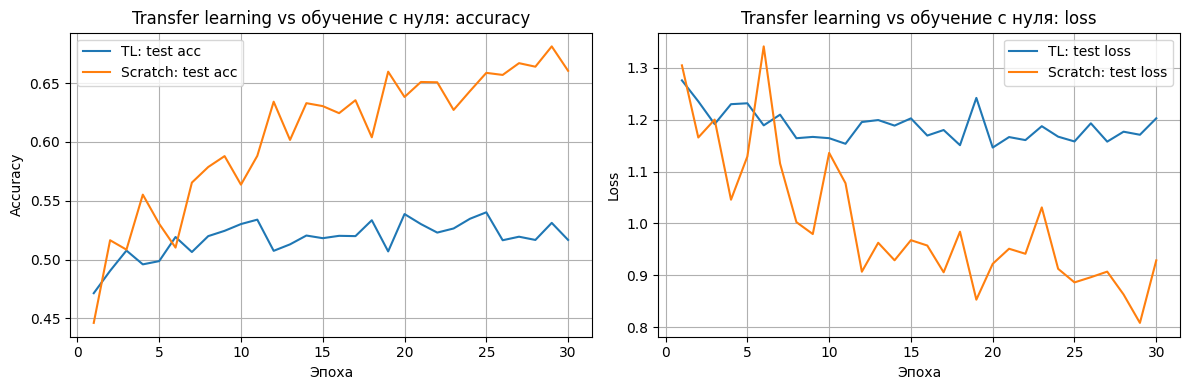

Финальная test accuracy (TL)     : 0.5168
Финальная test accuracy (Scratch): 0.6605


In [21]:
epochs = np.arange(1, num_epochs_tl + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_tl["test_acc"], label="TL: test acc")
plt.plot(epochs, history_scratch["test_acc"], label="Scratch: test acc")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Transfer learning vs обучение с нуля: accuracy")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history_tl["test_loss"], label="TL: test loss")
plt.plot(epochs, history_scratch["test_loss"], label="Scratch: test loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Transfer learning vs обучение с нуля: loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

print(f"Финальная test accuracy (TL)     : {history_tl['test_acc'][-1]:.4f}")
print(f"Финальная test accuracy (Scratch): {history_scratch['test_acc'][-1]:.4f}")

## 8. Ваш анализ: transfer learning против обучения с нуля

Здесь особенно важно написать **свой** анализ, а не универсальные фразы.  
Ориентировочно ответьте:

- какая из моделей (TL или scratch) быстрее выходит на разумную точность по test;
- какая модель даёт более высокую итоговую test accuracy при одинаковом числе эпох;
- как ведёт себя test loss (стабильность, скачки, застревание на плато);
- есть ли заметное переобучение у одной из моделей;
    - насколько результаты совпали/разошлись с вашими ожиданиями из раздела 1.


In [26]:
comparison_comment = """
1. Не сказал бы, что одна из моделей выходит на разумную точность, но scratch хотябы демонстрирует динамику обучение. TL же, после 7 эпохи, просто стоит на месте, не показывая признаков обучения
2. scratch показывает более лучшие результаты, чем TL (0.66 accuracy против 0.51 на 30 эпохе)
3. loss график обоих моделей не характеризуется стабильностью, а изменяется скачаками. TL, кроме того, еще и застревает на плато
4. Ожидания, что модели проявят себя не лучшим образом, оправдались. Все-таки данные слишком разнятся
"""
print(comparison_comment)


1. Не сказал бы, что одна из моделей выходит на разумную точность, но scratch хотябы демонстрирует динамику обучение. TL же, после 7 эпохи, просто стоит на месте, не показывая признаков обучения
2. scratch показывает более лучшие результаты, чем TL (0.66 accuracy против 0.51 на 30 эпохе)
3. loss график обоих моделей не характеризуется стабильностью, а изменяется скачаками. TL, кроме того, еще и застревает на плато
4. Ожидания, что модели проявят себя не лучшим образом, оправдались. Все-таки данные слишком разнятся



## 8.5. (Задание со звездочкой) Почему transfer learning не сработал?

Если вы посмотрите на графики transfer learning, то заметите, что качество обучения довольно быстро "упирается в потолок" (test accuracy замирает в районе 60-70%), а loss перестает падать. 
Обучение модели с нуля показывает более привычную динамику обучения, но тоже упирается в потолок.

**Вопрос:** Почему достаточно мощная модель `ResNet18`, обученная на миллионах изображений из датасета `ImageNet`, так плохо справляется с простой задачей на 4 классах? 

Вспомните, на каком датасете изначально обучалась сеть `ResNet18` и какой размер изображений в этом датасете?
Какой размер изображений в датасете `CIFAR-10`?
Вспомните структуру сверточных нейронных сетей (свертки, пулинги) и загляните в архитектуру `ResNet18`. 
Что происходит с пространственным размером картинки по мере прохождения через слои сети? 
Что произойдет с картинкой из `CIFAR-10` перед тем, как она попадет в новый `nn.Linear` слой?

### Ваша задача:
1. **Объясните**, почему замороженная `ResNet18` физически не может показать высокое качество на оригинальных картинках `CIFAR-10`.
2. **Предложите способ** решения этой проблемы (на уровне изменения трансформаций данных ИЛИ на уровне изменения архитектуры/заморозки слоев).
3. **Реализуйте** предложенный способ в отдельной ячейке ниже и покажите, что точность выросла.

*Примечание - можно гуглить и спрашивать LLM*

In [ ]:
star_answer = """
1. Потому что картинки слишком разные. Пулинги ResNet18, обученной на больших картинках, не подходят для работы с маленькими картинками CIFAR-10
2. Если увеличивать размер CIFAR-10 до 224х224, то это может помочь, но время работы модели увеличится, мы не получим никаких приемуществ
"""
print(star_answer)

In [44]:
base_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# адаптация под CIFAR
base_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
base_model.maxpool = nn.Identity()

# НЕ замораживаем всё!
for param in base_model.parameters():
    param.requires_grad = True

# меняем голову
num_ftrs = base_model.fc.in_features
base_model.fc = nn.Linear(num_ftrs, num_target_classes)

model_tl = base_model.to(device)
optimizer_tl = torch.optim.Adam(model_tl.parameters(), lr=3e-4)

In [45]:

num_epochs_tl = 20

history_tl = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs_tl + 1):
    train_loss, train_acc = train_one_epoch_tl(model_tl, train_loader, optimizer_tl, criterion, device)
    test_loss, test_acc = evaluate_tl(model_tl, test_loader, criterion, device)

    history_tl["train_loss"].append(train_loss)
    history_tl["train_acc"].append(train_acc)
    history_tl["test_loss"].append(test_loss)
    history_tl["test_acc"].append(test_acc)

    print(f"[TL] Эпоха {epoch}/{num_epochs_tl}: "
          f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
          f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")


[TL] Эпоха 1/20: train_loss=1.0253, train_acc=0.5878, test_loss=0.8252, test_acc=0.6770
[TL] Эпоха 2/20: train_loss=0.6346, train_acc=0.7509, test_loss=0.7012, test_acc=0.7405
[TL] Эпоха 3/20: train_loss=0.5135, train_acc=0.8056, test_loss=0.6595, test_acc=0.7548
[TL] Эпоха 4/20: train_loss=0.4298, train_acc=0.8341, test_loss=0.6910, test_acc=0.7550
[TL] Эпоха 5/20: train_loss=0.3615, train_acc=0.8566, test_loss=0.6337, test_acc=0.7907
[TL] Эпоха 6/20: train_loss=0.2746, train_acc=0.8950, test_loss=0.6058, test_acc=0.8025
[TL] Эпоха 7/20: train_loss=0.2730, train_acc=0.9000, test_loss=0.7092, test_acc=0.7692
[TL] Эпоха 8/20: train_loss=0.2358, train_acc=0.9178, test_loss=0.5637, test_acc=0.8175
[TL] Эпоха 9/20: train_loss=0.2093, train_acc=0.9256, test_loss=0.5832, test_acc=0.8107
[TL] Эпоха 10/20: train_loss=0.1771, train_acc=0.9406, test_loss=0.6854, test_acc=0.8070
[TL] Эпоха 11/20: train_loss=0.1711, train_acc=0.9378, test_loss=0.7485, test_acc=0.7785
[TL] Эпоха 12/20: train_loss=0

In [ ]:
# я не знаю почему не сохранилась история, по переменным выше видно, что с +- 10 эпохи пошло переобучение
# вывод - уменьшаем кол-во эпох, чтоб не переобучаться
# я не хочу это пересчитывать, мой ноут этого не переживет, Илья Иванович, пожалейте, я понял эту тему, честное мужское слово

plt.figure()
plt.plot(history_tl["train_loss"], label="train_loss")
plt.plot(history_tl["test_loss"], label="test_loss")
plt.legend()
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.figure()
plt.plot(history_tl["train_acc"], label="train_acc")
plt.plot(history_tl["test_acc"], label="test_acc")
plt.legend()
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()


NameError: name 'history_tl' is not defined

<Figure size 640x480 with 0 Axes>

## 9. Итоговые выводы по лабораторной

В заключение сформулируйте короткое резюме (5–8 предложений):
- в каких случаях вы после этой работы **в первую очередь** будете пробовать transfer learning и почему;
- когда, по вашему мнению, имеет смысл всё-таки обучать модель с нуля (и зачем);
- какие настройки (заморозка слоёв, lr, число эпох, размер подвыборки) вы считаете для себя "разумными по умолчанию" после проведённых экспериментов.

Пишите так, чтобы вы сами, открыв этот ноутбук через полгода, смогли быстро вспомнить, что вы поняли про transfer learning.


In [ ]:
final_summary = """
1. Использовать transfer learning уместно в случае, когда входные данные схожи с теми, на которых модель училась
2. Обучать модель с нуля стоит, когда данные сильно отличаются от тех, на которых обучалась предобученная модель, так как в этом случае модель может адаптироваться к особенностям новых данных
3. Не знаю, никакие, абсолютно не понравилось использовать transfer learning в данной задаче, так как данные слишком разнятся. 
Модель просто не может адаптироваться и показывает плохую точность 
"""
print(final_summary)